# Phase 3 - Analisis de Segmentos (Manual + Automatico + IA)

Este notebook analiza el dataset unificado de segmentos de **USDJPY**:

- Segmentos manuales
- Segmentos automaticos (beyond_sota)
- Segmentos por IA (Chronos)

Incluye:

1. Perfil general de datos
2. Analisis de tamanos y duracion
3. Distribuciones por origen
4. Timeline temporal de segmentos
5. Etiquetas/patrones dominantes
6. Visualizacion de ejemplos sobre la serie de precio con `matplotlib`


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 260)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    pass


In [2]:
# =========================
# Config
# =========================
SEGMENTS_PATH = Path('./phases/phase02_market_alphabet/output_segments_unificados/USDJPY_segments_todos_unificados.parquet')
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet')

OUTPUT_DIR = Path('./phases/phase03_segment_analysis/output_eda')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_SEGMENTS_PARQUET = OUTPUT_DIR / 'USDJPY_segments_unificados_enriquecidos.parquet'
SUMMARY_CSV = OUTPUT_DIR / 'USDJPY_segments_summary_por_origen.csv'

TOP_EXAMPLES = 12
PAD_BARS = 72

print('SEGMENTS_PATH =', SEGMENTS_PATH)
print('PRICE_PATH =', PRICE_PATH)
print('OUTPUT_DIR =', OUTPUT_DIR)


SEGMENTS_PATH = ./phases/phase02_market_alphabet/output_segments_unificados/USDJPY_segments_todos_unificados.parquet
PRICE_PATH = ./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet
OUTPUT_DIR = ./phases/phase03_segment_analysis/output_eda


In [3]:
# =========================
# Helpers
# =========================
def load_segments(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe: {path}')

    df = pd.read_parquet(path).copy()

    for c in ['start_ts', 'end_ts', 'created_at']:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors='coerce')

    for c in ['start_idx', 'end_idx', 'n_bars', 'range_pips', 'move_pips', 'abs_move_pips', 'net_move_pips', 'score', 'peak_score']:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')

    # Features unificadas entre fuentes
    if 'net_move_pips' in df.columns and 'move_pips' in df.columns:
        df['move_pips_unified'] = df['net_move_pips'].where(df['net_move_pips'].notna(), df['move_pips'])
    elif 'move_pips' in df.columns:
        df['move_pips_unified'] = df['move_pips']
    else:
        df['move_pips_unified'] = np.nan

    if 'abs_move_pips' in df.columns:
        df['abs_move_pips_unified'] = df['abs_move_pips']
        miss = df['abs_move_pips_unified'].isna()
        df.loc[miss, 'abs_move_pips_unified'] = df.loc[miss, 'move_pips_unified'].abs()
    else:
        df['abs_move_pips_unified'] = df['move_pips_unified'].abs()

    if 'range_pips' in df.columns:
        df['range_pips_unified'] = df['range_pips']
    else:
        df['range_pips_unified'] = np.nan

    if 'peak_score' in df.columns and 'score' in df.columns:
        df['score_unified'] = df['peak_score'].where(df['peak_score'].notna(), df['score'])
    elif 'score' in df.columns:
        df['score_unified'] = df['score']
    else:
        df['score_unified'] = np.nan

    # Etiqueta unificada
    candidates = [c for c in ['pattern_type', 'label', 'proxy_label', 'subtype', 'dominant_event'] if c in df.columns]
    df['segment_label_unified'] = pd.Series(pd.NA, index=df.index, dtype='string')
    for c in candidates:
        m = df['segment_label_unified'].isna() & df[c].notna()
        df.loc[m, 'segment_label_unified'] = df.loc[m, c].astype('string')

    # Duracion temporal
    if 'start_ts' in df.columns and 'end_ts' in df.columns:
        dur_hours = (df['end_ts'] - df['start_ts']).dt.total_seconds() / 3600.0
        df['duration_hours'] = dur_hours + 1.0
    else:
        df['duration_hours'] = np.nan

    # Fallback duracion por barras
    if 'n_bars' in df.columns:
        m = df['duration_hours'].isna()
        df.loc[m, 'duration_hours'] = df.loc[m, 'n_bars']

    return df


def load_price(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe: {path}')

    df = pd.read_parquet(path, columns=['timestamp', 'open', 'high', 'low', 'close']).copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    for c in ['open', 'high', 'low', 'close']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['timestamp', 'close'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
    return df


def order_origins(df: pd.DataFrame) -> list[str]:
    pref = ['manual', 'automatico', 'ia']
    have = [x for x in pref if x in set(df['segment_origin'].dropna().astype(str))]
    rest = sorted([x for x in set(df['segment_origin'].dropna().astype(str)) if x not in set(pref)])
    return have + rest


In [4]:
# =========================
# Carga
# =========================
SEG = load_segments(SEGMENTS_PATH)
PX = load_price(PRICE_PATH)

print(f'Segmentos: {len(SEG):,} | Columnas: {len(SEG.columns)}')
print(f'Precio H1: {len(PX):,} | Rango: {PX.timestamp.min()} -> {PX.timestamp.max()}')
print('Conteo por origen:')
print(SEG['segment_origin'].value_counts(dropna=False).to_string())

display(SEG.head(5))


Segmentos: 1,024 | Columnas: 48
Precio H1: 155,465 | Rango: 2000-05-30 17:00:00 -> 2025-12-05 16:00:00
Conteo por origen:
segment_origin
automatico    430
manual        389
ia            205


,method,subtype,start_idx,end_idx,start_ts,end_ts,n_bars,move_pips,abs_move_pips,range_pips,rv_inside,rv_prev,vol_ratio,trend_r2,slope,score_base,symbol,asset_path,score,proxy_label,seq_id,cluster_id,segment_origin,source_name,source_file,row_id,label,quality,notes,created_at,source,n_events,dominant_event,mean_score,peak_score,net_move_pips,source_model,start_price,end_price,segment_id,pattern_type,global_segment_id,move_pips_unified,abs_move_pips_unified,range_pips_unified,score_unified,segment_label_unified,duration_hours
0,pivot,impulse_up,0,18,2015-01-01 13:00:00,2015-01-02 09:00:00,19,95.199585,95.199585,107.599640,0.000624,0.000624,1.000000,0.831103,0.047804,21.840283,USDJPY,./data/parquet_...,4.370705,impulse_up,90.0,7.0,automatico,beyond_sota,./phase2: alfab...,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,beyond_sota_000090,95.199585,95.199585,107.599640,4.370705,impulse_up,21.0
1,pivot,impulse_up,19,26,2015-01-02 10:00:00,2015-01-04 17:00:00,8,33.699799,33.699799,81.400299,0.001530,0.000624,2.451769,0.947268,0.050726,11.914678,USDJPY,./data/parquet_...,2.747459,impulse_up,180.0,7.0,automatico,beyond_sota,./phase2: alfab...,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,beyond_sota_000180,33.699799,33.699799,81.400299,2.747459,impulse_up,56.0
2,cusum,shock_down,30,54,2015-01-04 21:00:00,2015-01-05 21:00:00,25,-99.700165,99.700165,148.699951,0.001392,0.001069,1.302602,0.872792,-0.057365,4.799999,USDJPY,./data/parquet_...,2.137900,shock_down,235.0,6.0,automatico,beyond_sota,./phase2: alfab...,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,beyond_sota_000235,-99.700165,99.700165,148.699951,2.137900,shock_down,25.0
3,pivot,impulse_down,53,58,2015-01-05 20:00:00,2015-01-06 01:00:00,6,-65.100098,65.100098,79.599762,0.001439,0.001342,1.072589,0.911964,-0.126800,26.577004,USDJPY,./data/parquet_...,4.652763,impulse_down,77.0,6.0,automatico,beyond_sota,./phase2: alfab...,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,beyond_sota_000077,-65.100098,65.100098,79.599762,4.652763,impulse_down,6.0
4,pivot,impulse_down,63,68,2015-01-06 06:00:00,2015-01-06 11:00:00,6,-109.600067,109.600067,119.100189,0.002114,0.001594,1.326093,0.903012,-0.189914,44.744040,USDJPY,./data/parquet_...,8.680612,impulse_down,9.0,3.0,automatico,beyond_sota,./phase2: alfab...,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,beyond_sota_000009,-109.600067,109.600067,119.100189,8.680612,impulse_down,6.0


In [5]:
# =========================
# Calidad de datos
# =========================
dup_gid = SEG['global_segment_id'].duplicated().sum() if 'global_segment_id' in SEG.columns else np.nan
neg_duration = int((SEG['duration_hours'] <= 0).sum()) if 'duration_hours' in SEG.columns else np.nan
invalid_idx = int((SEG['end_idx'] < SEG['start_idx']).sum()) if {'start_idx','end_idx'}.issubset(SEG.columns) else np.nan

print('Duplicados global_segment_id:', dup_gid)
print('Duracion <= 0:', neg_duration)
print('end_idx < start_idx:', invalid_idx)

na_report_cols = [c for c in ['n_bars','duration_hours','range_pips_unified','move_pips_unified','score_unified','segment_label_unified'] if c in SEG.columns]
na_report = pd.DataFrame({
    'column': na_report_cols,
    'non_null': [int(SEG[c].notna().sum()) for c in na_report_cols],
    'nulls': [int(SEG[c].isna().sum()) for c in na_report_cols],
})
display(na_report)


Duplicados global_segment_id: 0
Duracion <= 0: 0
end_idx < start_idx: 0


,column,non_null,nulls
0,n_bars,1024,0
1,duration_hours,1024,0
2,range_pips_unified,635,389
3,move_pips_unified,635,389
4,score_unified,635,389
5,segment_label_unified,1024,0


In [6]:
# =========================
# Resumen por origen
# =========================
summary = (
    SEG.groupby('segment_origin', dropna=False)
    .agg(
        segments=('global_segment_id', 'count'),
        median_bars=('n_bars', 'median'),
        p90_bars=('n_bars', lambda s: float(np.nanpercentile(s.dropna(), 90)) if s.notna().any() else np.nan),
        median_duration_h=('duration_hours', 'median'),
        median_abs_move_pips=('abs_move_pips_unified', 'median'),
        median_range_pips=('range_pips_unified', 'median'),
        median_score=('score_unified', 'median'),
    )
    .reset_index()
)
summary = summary.sort_values('segments', ascending=False).reset_index(drop=True)

display(summary)
summary.to_csv(SUMMARY_CSV, index=False)
print('Guardado summary:', SUMMARY_CSV)


,segment_origin,segments,median_bars,p90_bars,median_duration_h,median_abs_move_pips,median_range_pips,median_score
0,automatico,430,9.0,17.0,9.0,50.300217,64.099884,2.376638
1,manual,389,16.0,43.0,16.0,NaN,NaN,NaN
2,ia,205,17.0,17.0,17.0,22.299957,57.299805,1.205536


Guardado summary: ./phases/phase03_segment_analysis/output_eda/USDJPY_segments_summary_por_origen.csv


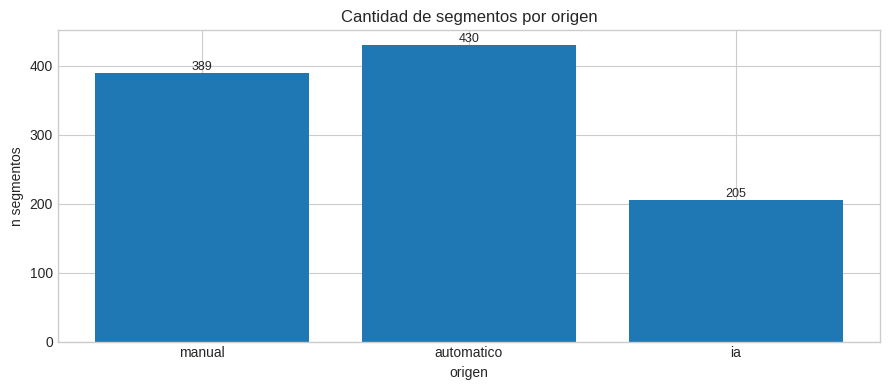

In [7]:
# =========================
# Grafico 1: cantidad por origen
# =========================
ord_ = order_origins(SEG)
counts = SEG['segment_origin'].value_counts().reindex(ord_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(counts.index.astype(str), counts.values)
ax.set_title('Cantidad de segmentos por origen')
ax.set_xlabel('origen')
ax.set_ylabel('n segmentos')
for i, v in enumerate(counts.values):
    ax.text(i, v, str(int(v)), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()


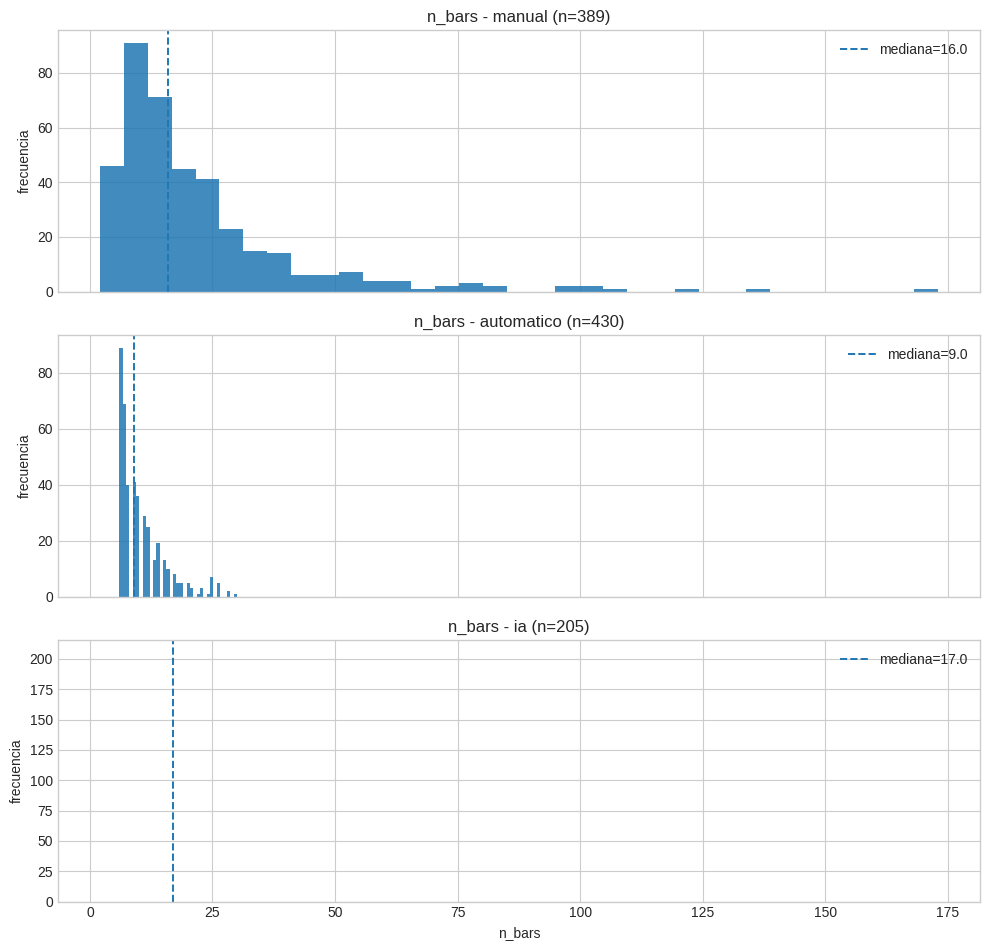

In [8]:
# =========================
# Grafico 2: distribucion de tamano (n_bars)
# =========================
ord_ = order_origins(SEG)
fig, axes = plt.subplots(len(ord_), 1, figsize=(10, 3.2 * max(1, len(ord_))), sharex=True)
if len(ord_) == 1:
    axes = [axes]

for ax, origin in zip(axes, ord_):
    s = SEG.loc[SEG['segment_origin'] == origin, 'n_bars'].dropna()
    if len(s) == 0:
        ax.text(0.5, 0.5, f'Sin datos para {origin}', ha='center', va='center')
        continue
    ax.hist(s, bins=35, alpha=0.85)
    ax.axvline(s.median(), linestyle='--', linewidth=1.4, label=f'mediana={s.median():.1f}')
    ax.set_title(f'n_bars - {origin} (n={len(s)})')
    ax.set_ylabel('frecuencia')
    ax.legend(loc='upper right')

axes[-1].set_xlabel('n_bars')
plt.tight_layout()
plt.show()


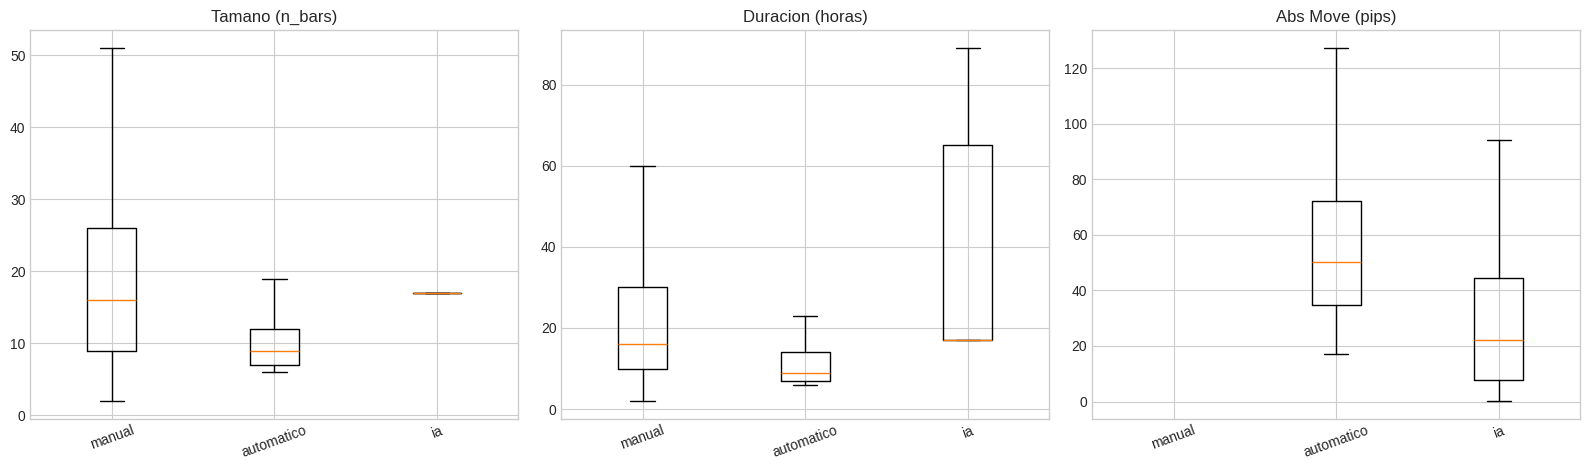

In [9]:
# =========================
# Grafico 3: boxplots comparativos
# =========================
ord_ = order_origins(SEG)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
metrics = [
    ('n_bars', 'Tamano (n_bars)'),
    ('duration_hours', 'Duracion (horas)'),
    ('abs_move_pips_unified', 'Abs Move (pips)'),
]

for ax, (col, title) in zip(axes, metrics):
    data = [SEG.loc[SEG['segment_origin'] == o, col].dropna().to_numpy() for o in ord_]
    non_empty = [len(x) > 0 for x in data]
    if not any(non_empty):
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(title)
        continue

    # Mantener posiciones incluso si algun origen queda vacio
    plot_data = [d if len(d) > 0 else np.array([np.nan]) for d in data]
    ax.boxplot(plot_data, tick_labels=ord_, showfliers=False)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


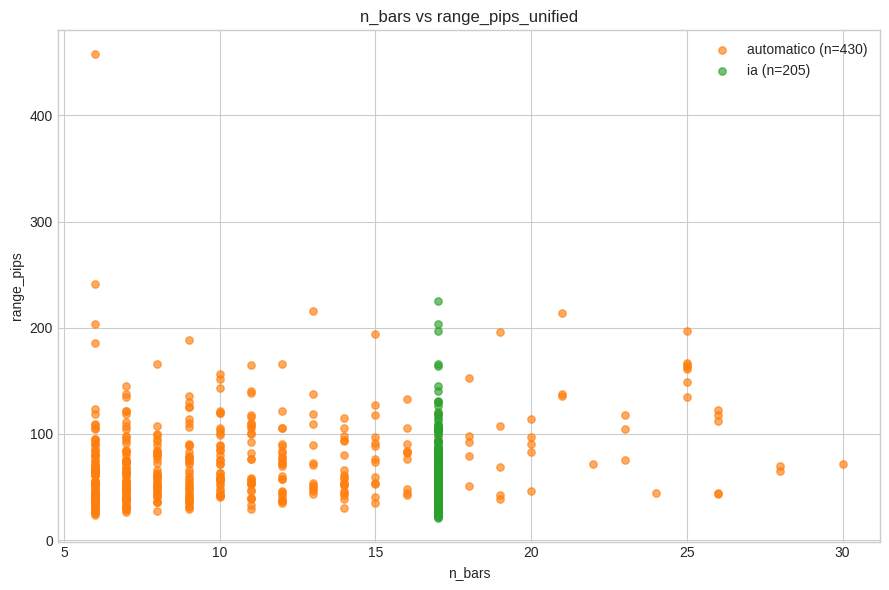

In [10]:
# =========================
# Grafico 4: dispersion tamano vs rango
# =========================
ord_ = order_origins(SEG)
colors = {
    'manual': '#1f77b4',
    'automatico': '#ff7f0e',
    'ia': '#2ca02c',
}

fig, ax = plt.subplots(figsize=(9, 6))
for o in ord_:
    d = SEG[(SEG['segment_origin'] == o) & SEG['n_bars'].notna() & SEG['range_pips_unified'].notna()]
    if d.empty:
        continue
    ax.scatter(
        d['n_bars'],
        d['range_pips_unified'],
        s=28,
        alpha=0.65,
        color=colors.get(o, None),
        label=f'{o} (n={len(d)})',
    )

ax.set_title('n_bars vs range_pips_unified')
ax.set_xlabel('n_bars')
ax.set_ylabel('range_pips')
ax.legend()
plt.tight_layout()
plt.show()


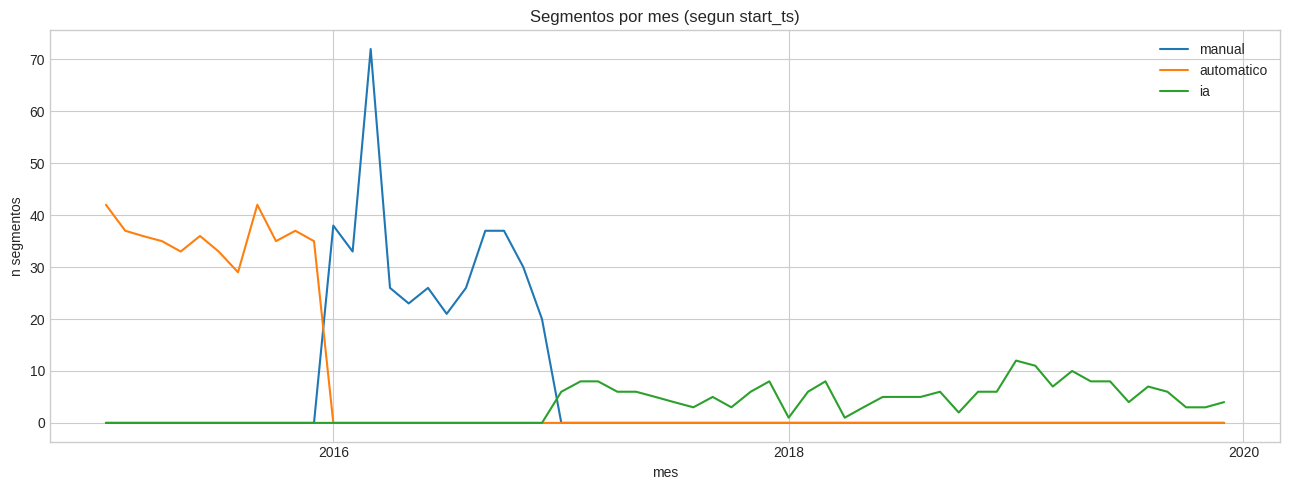

In [11]:
# =========================
# Grafico 5: timeline mensual de inicios
# =========================
if 'start_ts' not in SEG.columns:
    raise ValueError('No existe start_ts en SEG')

tmp = SEG.dropna(subset=['start_ts']).copy()
tmp['month'] = tmp['start_ts'].dt.to_period('M').dt.to_timestamp()
monthly = (
    tmp.groupby(['month', 'segment_origin'], dropna=False)
    .size()
    .reset_index(name='n')
)

pivot = monthly.pivot(index='month', columns='segment_origin', values='n').fillna(0).sort_index()
ord_ = [o for o in order_origins(SEG) if o in pivot.columns]
pivot = pivot[ord_]

fig, ax = plt.subplots(figsize=(13, 5))
for o in ord_:
    ax.plot(pivot.index, pivot[o], label=o)

ax.set_title('Segmentos por mes (segun start_ts)')
ax.set_xlabel('mes')
ax.set_ylabel('n segmentos')
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator(base=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()


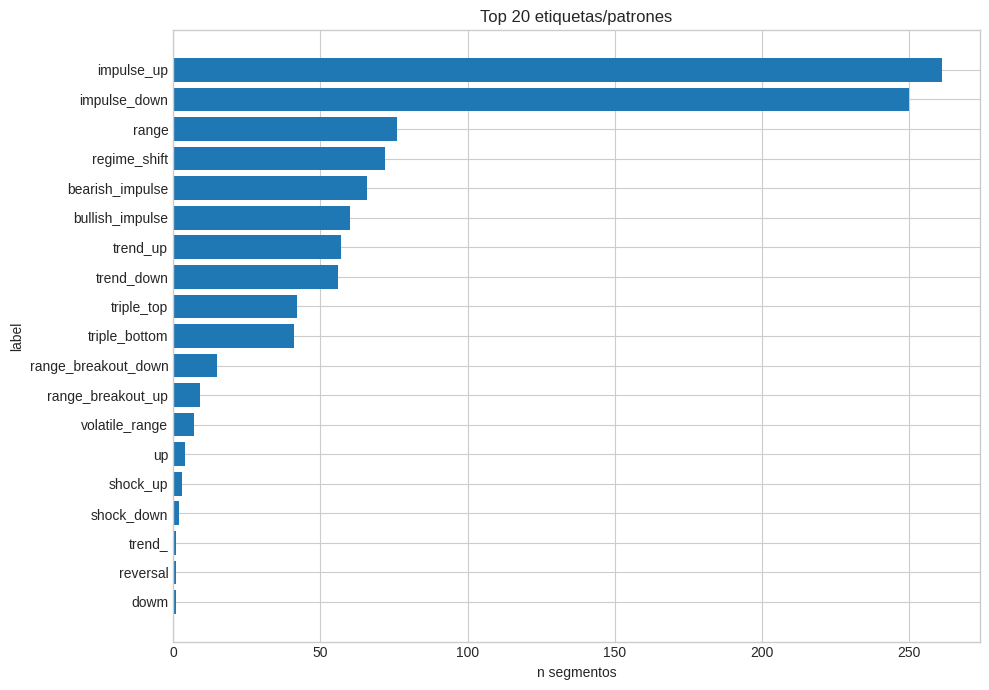

In [12]:
# =========================
# Grafico 6: top etiquetas/patrones
# =========================
lab = SEG['segment_label_unified'].dropna().astype(str)
if lab.empty:
    print('No hay etiquetas disponibles en segment_label_unified')
else:
    top = lab.value_counts().head(20)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top.index[::-1], top.values[::-1])
    ax.set_title('Top 20 etiquetas/patrones')
    ax.set_xlabel('n segmentos')
    ax.set_ylabel('label')
    plt.tight_layout()
    plt.show()


In [13]:
# =========================
# Visualizador de segmentos sobre precio
# =========================
PX_TS = PX.set_index('timestamp').sort_index()


def plot_segment_examples(seg_df: pd.DataFrame, title: str, top_n: int = 9, pad_bars: int = 72):
    if seg_df.empty:
        print(f'Sin segmentos para: {title}')
        return

    show = seg_df.copy()
    if 'score_unified' in show.columns and show['score_unified'].notna().any():
        show = show.sort_values('score_unified', ascending=False)
    elif 'abs_move_pips_unified' in show.columns and show['abs_move_pips_unified'].notna().any():
        show = show.sort_values('abs_move_pips_unified', ascending=False)

    show = show.head(top_n).reset_index(drop=True)

    n = len(show)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.8 * nrows), squeeze=False)

    for i in range(nrows * ncols):
        ax = axes[i // ncols][i % ncols]
        if i >= n:
            ax.axis('off')
            continue

        r = show.loc[i]
        s = pd.Timestamp(r['start_ts'])
        e = pd.Timestamp(r['end_ts'])

        i0 = PX_TS.index.searchsorted(s, side='left')
        i1 = PX_TS.index.searchsorted(e, side='right') - 1
        i0 = max(0, i0 - pad_bars)
        i1 = min(len(PX_TS) - 1, i1 + pad_bars)

        w = PX_TS.iloc[i0:i1 + 1].copy()
        if w.empty:
            ax.axis('off')
            continue

        ax.plot(w.index, w['close'], linewidth=1.1)
        ax.axvspan(s, e, alpha=0.22)

        label = str(r.get('segment_label_unified', 'NA'))
        origin = str(r.get('segment_origin', 'NA'))
        nb = r.get('n_bars', np.nan)
        rg = r.get('range_pips_unified', np.nan)

        ax.set_title(f'{origin} | bars={nb:.0f} | range={rg:.1f} | {label}', fontsize=9)
        ax.tick_params(axis='x', rotation=20)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


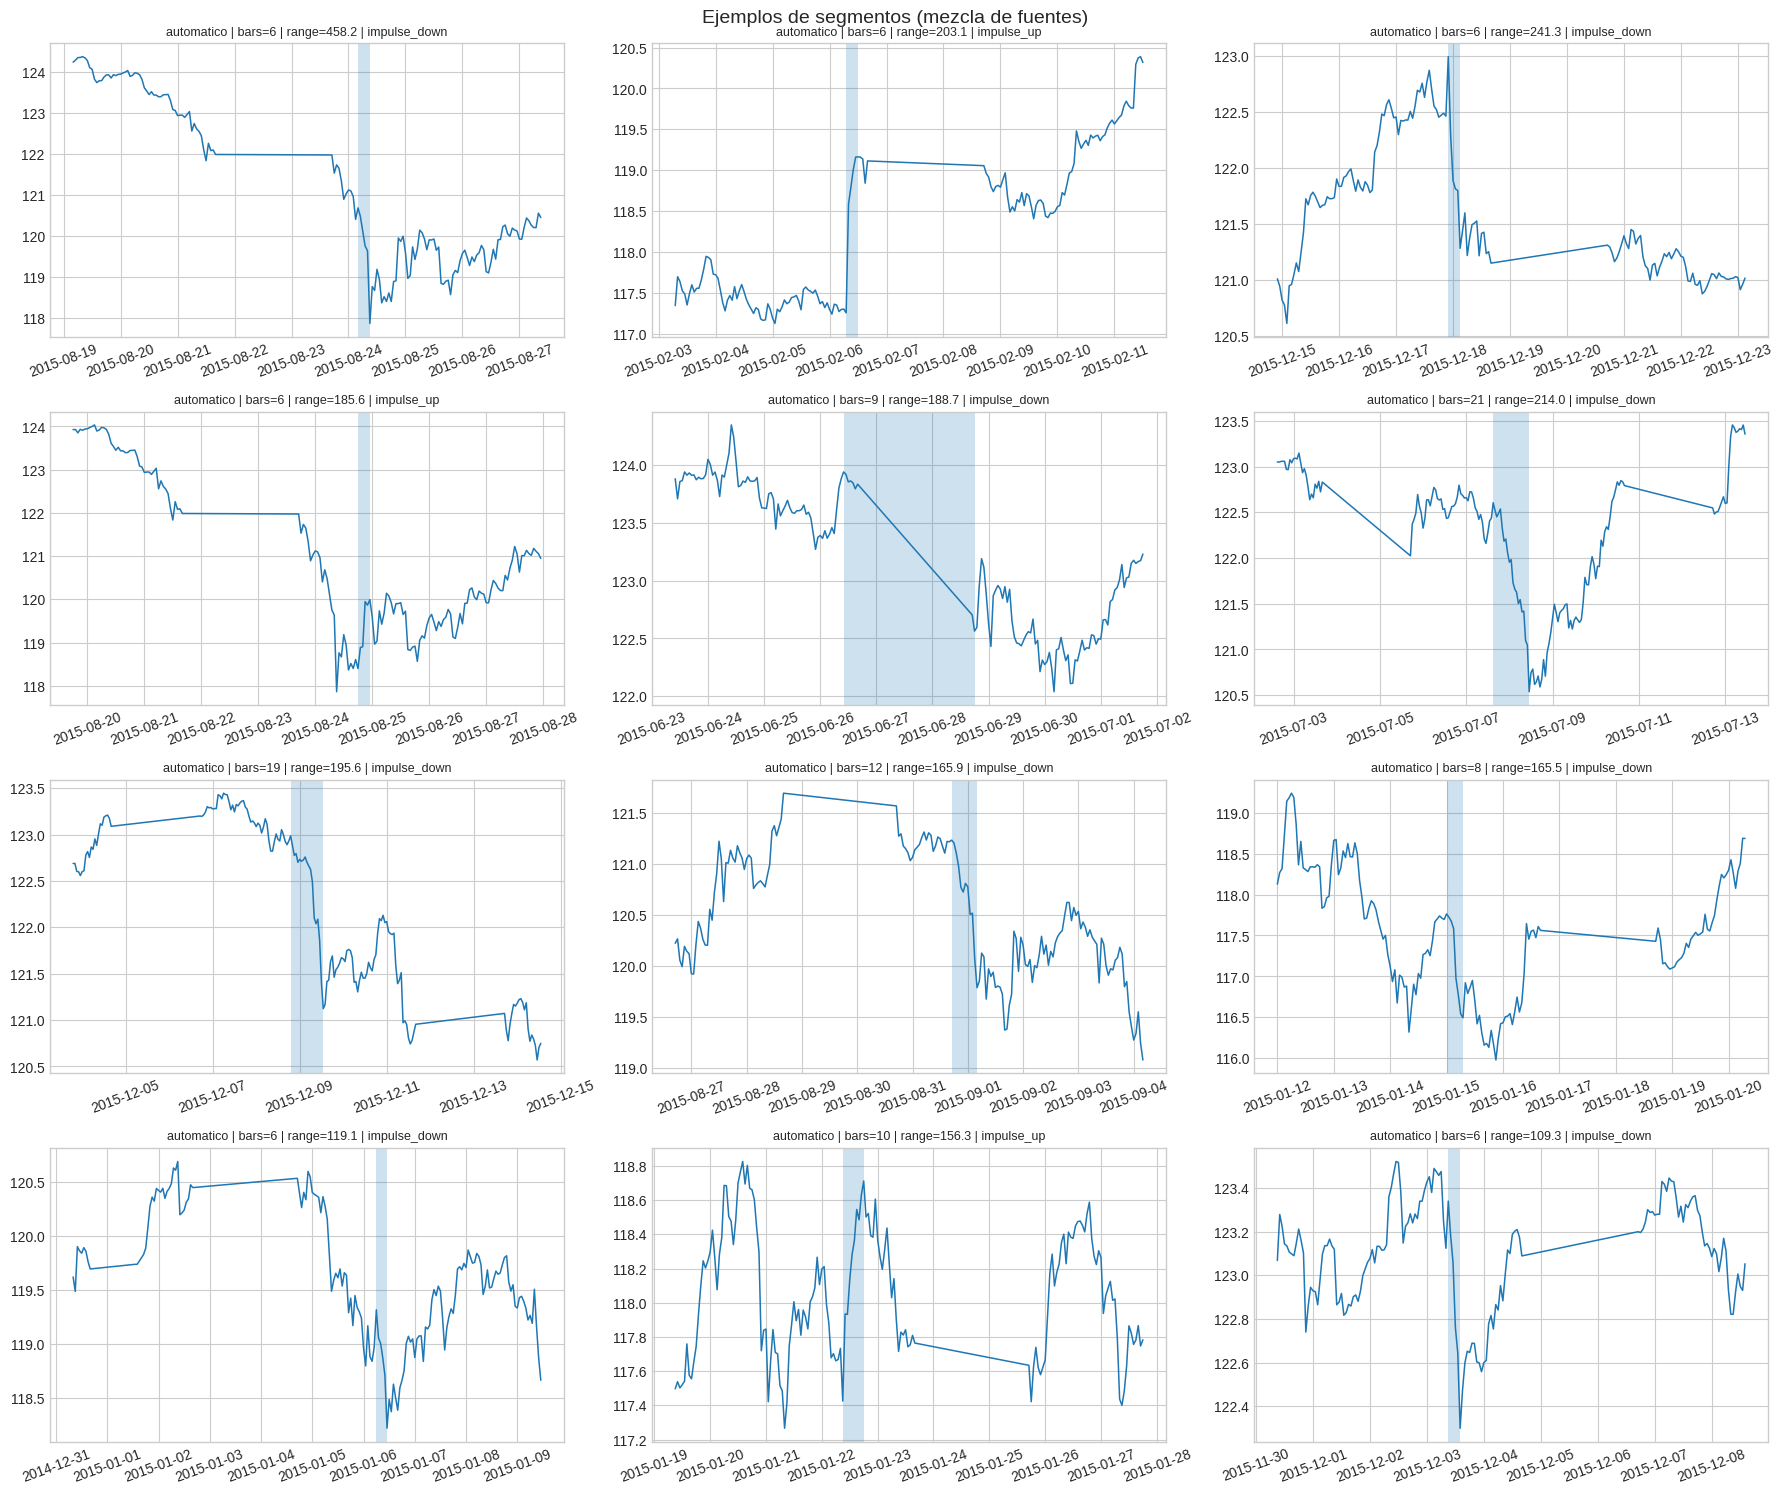

In [14]:
# =========================
# Ejemplos globales (top por score/move)
# =========================
plot_segment_examples(SEG, title='Ejemplos de segmentos (mezcla de fuentes)', top_n=TOP_EXAMPLES, pad_bars=PAD_BARS)


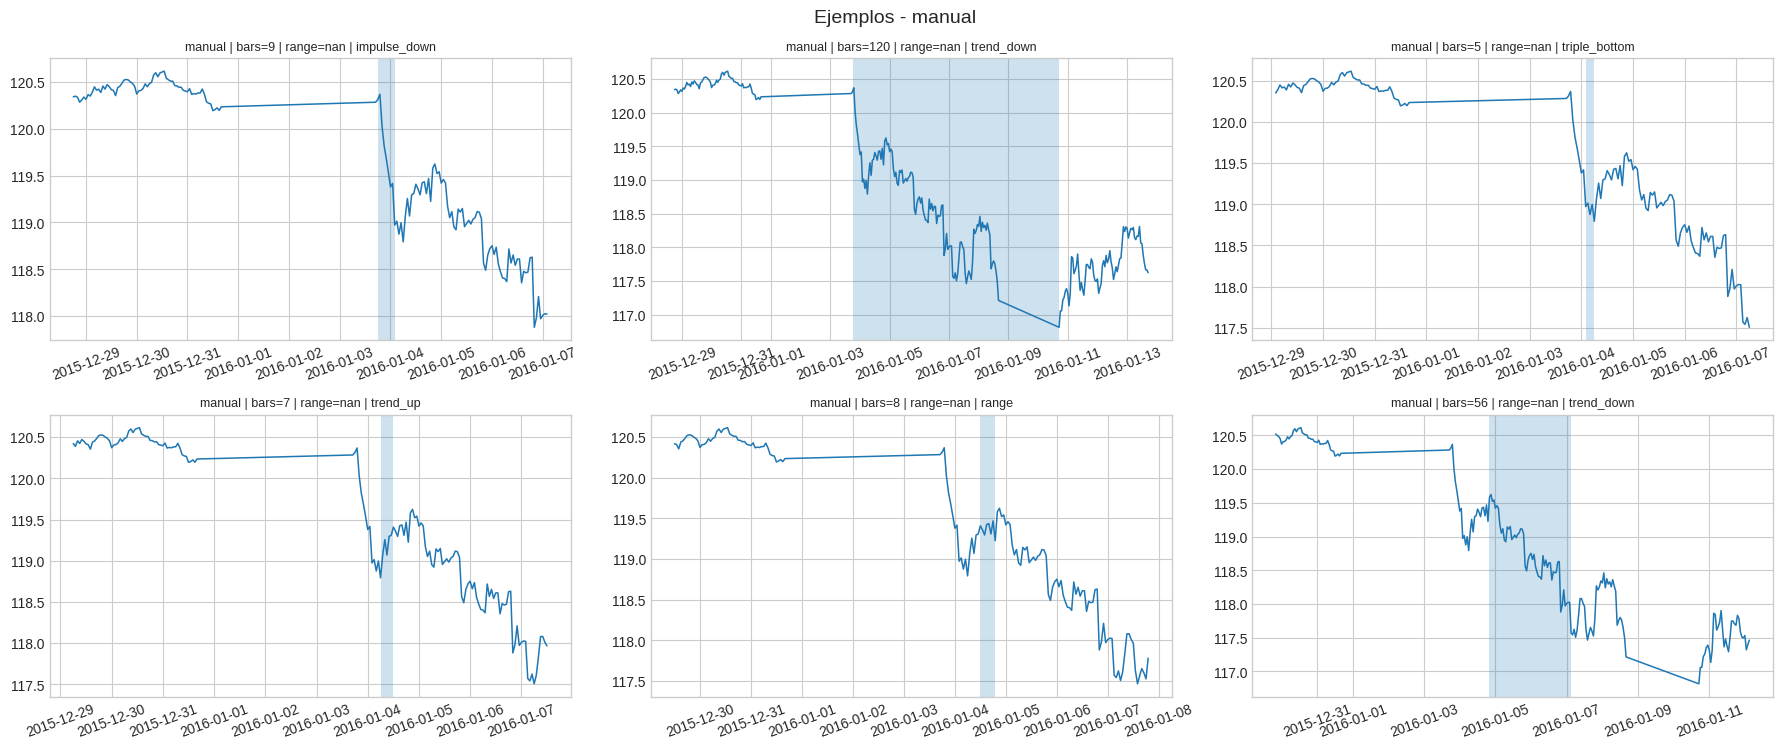

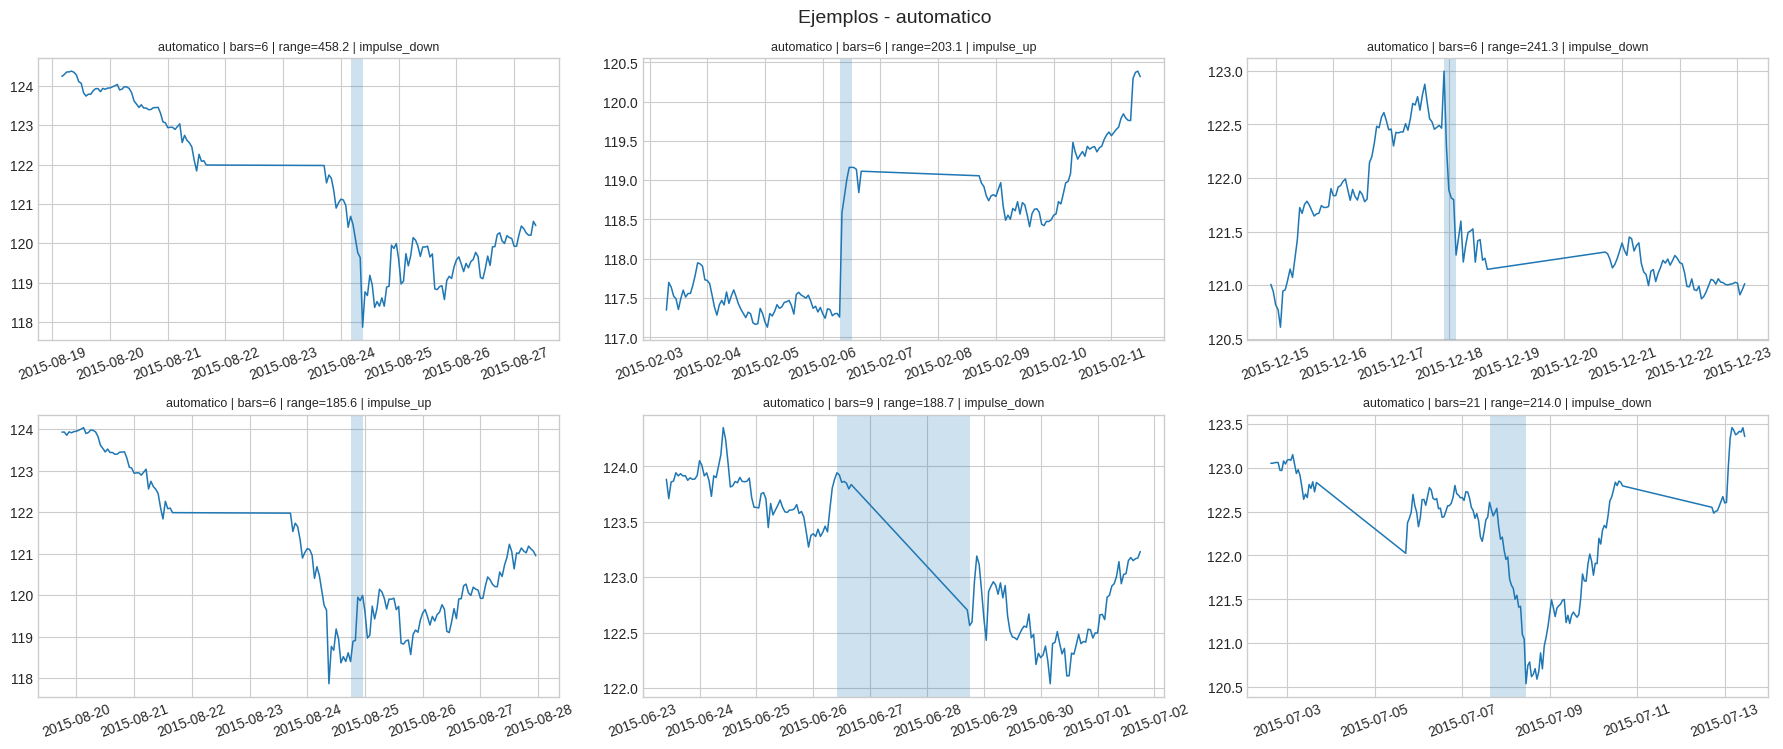

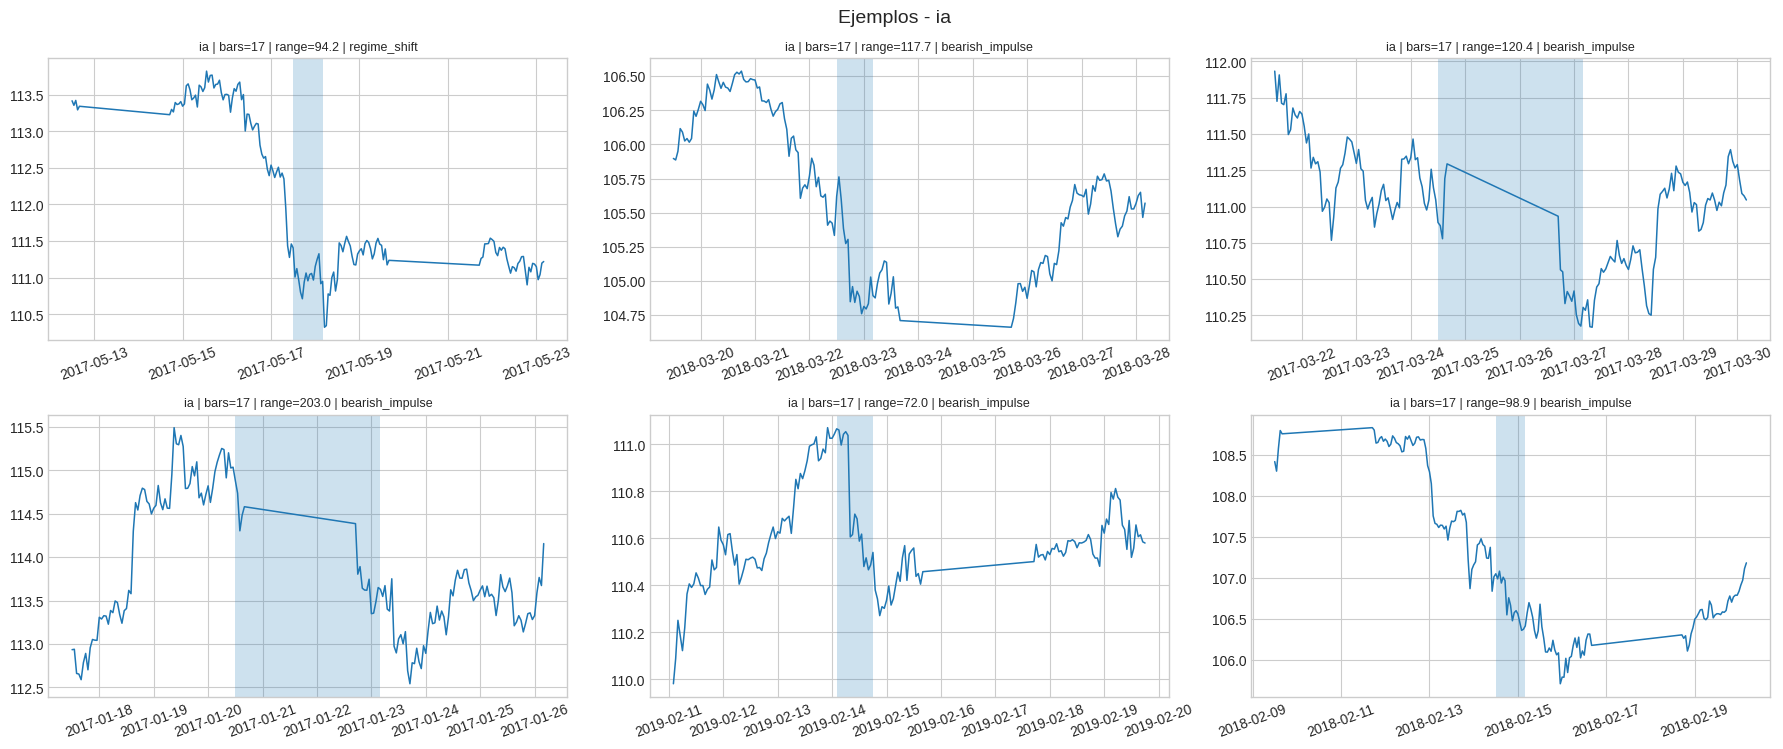

In [15]:
# =========================
# Ejemplos por origen
# =========================
for origin in order_origins(SEG):
    d = SEG[SEG['segment_origin'] == origin].copy()
    plot_segment_examples(d, title=f'Ejemplos - {origin}', top_n=6, pad_bars=PAD_BARS)


In [16]:
# =========================
# Export de dataset enriquecido
# =========================
SEG.to_parquet(CLEAN_SEGMENTS_PARQUET, index=False)

print('Guardado:')
print(' -', CLEAN_SEGMENTS_PARQUET)
print(' -', SUMMARY_CSV)


Guardado:
 - ./phases/phase03_segment_analysis/output_eda/USDJPY_segments_unificados_enriquecidos.parquet
 - ./phases/phase03_segment_analysis/output_eda/USDJPY_segments_summary_por_origen.csv


## Notas

- Este analisis usa **concatenacion por filas** (sin deduplicacion entre fuentes).
- Si quieres una version "master" sin solapes, el siguiente paso es crear reglas de deduplicacion temporal.
- El campo `segment_label_unified` mezcla fuentes y no representa una taxonomia unica; conviene normalizarlo si lo usaras en modelado supervisado.
